# 08 · Benchmarks: how good is FinSight Q&A, and how does it compare?

Three evaluations, all run **once per frozen configuration** (nothing here was used for tuning):

| Benchmark | What it measures | Size |
|---|---|---|
| **Test v1** (`rag_gold.json`) | direct statement lookups on our 6 Indian reports | 26 answerable + 4 unanswerable |
| **Test v2** (`rag_gold_v2.json`) | natural phrasing, computed ratios, growth, narrative, new unanswerables | 26 answerable + 4 unanswerable |
| **TAT-QA** (Zhu et al., ACL 2021), public | hybrid table + text QA over real (mostly US) annual reports, official EM/F1 | 300-question stratified dev sample |

Configurations: **D** (hybrid retrieval + cleaned KPI table, notebook 05), **H** (statement-aware LLM,
notebook 06) and **J** (deterministic table reader, then H as fallback; the live setting).

In [1]:
import json
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ml.paths import DATA_DIR, FIGURES_DIR, REPORTS_DIR
from ml.eval.score_runs import score, summarise
from ml.eval.reader_eval import evaluate as reader_evaluate
from ml.eval import tatqa_eval

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 120)
CONFIGS = {"D_hybrid_all_kpis": "D · hybrid + KPI table", "H_statements_no_kpi": "H · statement-aware LLM",
           "J_table_reader": "J · table reader → LLM (live)"}


def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"08_{name}.png", dpi=130)
    plt.show()


def ci(x, n=5000, seed=0):
    x = np.asarray(x, float)
    m = np.random.default_rng(seed).choice(x, (n, len(x))).mean(1)
    return np.percentile(m, [2.5, 97.5])


def table(qset):
    d = score(qset)
    d = d[d.config.isin(CONFIGS)]
    s = summarise(d).loc[[c for c in CONFIGS if c in set(d.config)]]
    ans = d[d.kind != "unanswerable"]
    bounds = {c: ci(ans[ans.config == c].numeric_correct.astype(float)) for c in s.index}
    s.insert(2, "ci", [f"{bounds[c][0]:.0%}–{bounds[c][1]:.0%}" for c in s.index])
    s.index = [CONFIGS[c] for c in s.index]
    return d, s

## 1. Test v1: direct statement lookups

In [2]:
d1, t1 = table("test")
t1

,n,accuracy,ci,unit_acc,fabricated,refusal_acc,median_s
D · hybrid + KPI table,26,0.653846,46%–85%,0.653846,0.000,1.0,4.275
H · statement-aware LLM,26,0.769231,62%–92%,0.769231,0.067,1.0,5.265
J · table reader → LLM (live),26,1.0,100%–100%,1.0,0.000,1.0,0.070


## 2. Test v2: harder, natural questions

In [3]:
d2, t2 = table("test2")
t2

,n,accuracy,ci,unit_acc,fabricated,refusal_acc,median_s
D · hybrid + KPI table,26,0.461538,27%–65%,0.461538,0.000,1.0,4.300
H · statement-aware LLM,26,0.653846,46%–85%,0.615385,0.067,1.0,4.945
J · table reader → LLM (live),26,0.846154,69%–96%,0.807692,0.067,1.0,3.915


In [4]:
kinds = d2[d2.kind != "unanswerable"].groupby(["kind", "config"]).numeric_correct.mean().unstack()[list(CONFIGS)]
kinds.columns = [CONFIGS[c] for c in kinds.columns]
kinds.round(2)

,D · hybrid + KPI table,H · statement-aware LLM,J · table reader → LLM (live)
kind,,,
amount,0.35,0.65,0.85
percent,0.5,0.5,1.0
ratio,1.0,0.5,0.5
text,1.0,1.0,1.0


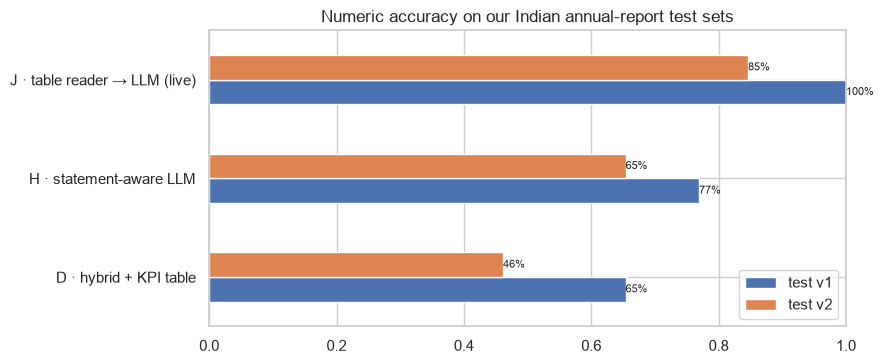

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
both = pd.DataFrame({"test v1": t1.accuracy, "test v2": t2.accuracy})
both.plot.barh(ax=ax)
ax.set_xlim(0, 1)
ax.set_title("Numeric accuracy on our Indian annual-report test sets")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", labels=[f"{v * 100:.0f}%" for v in c.datavalues], fontsize=8)
save("indian_tests")

## 3. The table reader on its own (no LLM)
The reader is the deterministic part of J. It answers only when confident; everything else goes to the LLM.

In [6]:
reader = {}
for qset in ("dev", "test", "test2"):
    _, s = reader_evaluate(qset, verbose=False)
    reader[qset] = s
reader_df = pd.DataFrame(reader).T[["questions", "coverage", "precision", "false_confident_on_unanswerable"]]
reader_df

2026-10-04 19:15:58.449 | INFO     | app.ml.page_classifier:_load:33 - Loaded PageClassifier from D:\annual-report-analyzer-main\models\page_classifier\model.joblib


2026-10-04 19:15:58.613 | INFO     | app.ml.statement_index:_build:77 - Statement index 1c9e78bb: 7 statement pages of 111


2026-10-04 19:16:00.923 | INFO     | app.ml.statement_index:_build:77 - Statement index 9a88fab0: 21 statement pages of 610


2026-10-04 19:16:04.249 | INFO     | app.ml.statement_index:_build:77 - Statement index 305f94a3: 13 statement pages of 396


2026-10-04 19:16:06.562 | INFO     | app.ml.statement_index:_build:77 - Statement index 9820853e: 33 statement pages of 414


2026-10-04 19:16:11.548 | INFO     | app.ml.statement_index:_build:77 - Statement index 45b2e41b: 30 statement pages of 424


2026-10-04 19:16:14.537 | INFO     | app.ml.statement_index:_build:77 - Statement index 8566cb3c: 7 statement pages of 303


,questions,coverage,precision,false_confident_on_unanswerable
dev,22.0,0.954545,1.0,0.0
test,25.0,0.960000,1.0,0.0
test2,24.0,0.333333,1.0,0.0


**Reading this.**
* **Precision** is the share of the reader's answers that are correct. It stays at 100% on every set:
  when it answers, it is right.
* **Coverage** drops from v1 to v2. Natural phrasing ("How much did *HAL spend on its employees*…",
  "…*on a consolidated basis*"), company names and computed ratios trip its strict "no extra qualifiers"
  guard, and those questions fall back to the LLM.
* Widening coverage without losing precision is the next reader improvement. It must be tuned on the dev
  set, never on v2.

## 4. TAT-QA (public benchmark, official metric)

In [7]:
tq = tatqa_eval.score(["llm", "reader"], 300)
tq_df = pd.DataFrame(tq).T
tq_df

,n,em,f1,scale_acc,modes,em_by_type
llm,300,15.33,18.96,49.33,{'llm': 300},"{'arithmetic': 4.7, 'count': 50.0, 'multi-span': 10.3, 'span': 26.2}"
reader,300,32.0,35.63,57.67,"{'llm': 237, 'reader': 63}","{'arithmetic': 32.6, 'count': 50.0, 'multi-span': 10.3, 'span': 37.3}"


In [8]:
published = pd.DataFrame([
    {"system": "Human experts", "EM": 84.1, "F1": 90.8, "split": "test", "source": "Zhu et al. 2021"},
    {"system": "TagOp (paper's model, RoBERTa-large, trained on TAT-QA)", "EM": 50.1, "F1": 58.0, "split": "test", "source": "Zhu et al. 2021"},
    {"system": "NumNet+ V2 (strongest baseline in the paper)", "EM": 37.0, "F1": 46.9, "split": "test", "source": "Zhu et al. 2021"},
    {"system": "FinSight J: table reader → Qwen2.5-3B (zero-shot, local)", "EM": tq["reader"]["em"], "F1": tq["reader"]["f1"], "split": "dev sample (300)", "source": "this notebook"},
    {"system": "FinSight: Qwen2.5-3B only (zero-shot, local)", "EM": tq["llm"]["em"], "F1": tq["llm"]["f1"], "split": "dev sample (300)", "source": "this notebook"},
])
published

,system,EM,F1,split,source
0,Human experts,84.10,90.80,test,Zhu et al. 2021
1,"TagOp (paper's model, RoBERTa-large, trained on TAT-QA)",50.10,58.00,test,Zhu et al. 2021
2,NumNet+ V2 (strongest baseline in the paper),37.00,46.90,test,Zhu et al. 2021
3,"FinSight J: table reader → Qwen2.5-3B (zero-shot, local)",32.00,35.63,dev sample (300),this notebook
4,"FinSight: Qwen2.5-3B only (zero-shot, local)",15.33,18.96,dev sample (300),this notebook


**Interpretation (honest comparison)**
* Our numbers are on a 300-question **dev** sample, while the published numbers are on the **test** split,
  whose answers are hidden. The comparison is indicative, not exact.
* The published systems were **trained on TAT-QA's 13k training questions**. Ours is **zero-shot**: a 3B
  model plus rules, never trained on TAT-QA, running on a 4 GB laptop GPU.
* The deterministic reader roughly **doubles** the zero-shot LLM, mostly on arithmetic questions, where a
  small LLM's arithmetic fails and Python's does not.
* Reader precision on TAT-QA is lower than on Indian reports. US/UK tables have different layouts and
  question styles. Its rules were inspected on this dev sample, so the honest estimate comes from a
  **separate, unseen** TAT-QA train sample: **85.5% precision at 19.8% coverage** (1,500 questions).
* Closing the gap to TagOp needs what TagOp had: training on financial table QA. That is FinSumm
  (`ml/FINETUNING.md`), and TAT-QA's train split could be added to its SFT data.

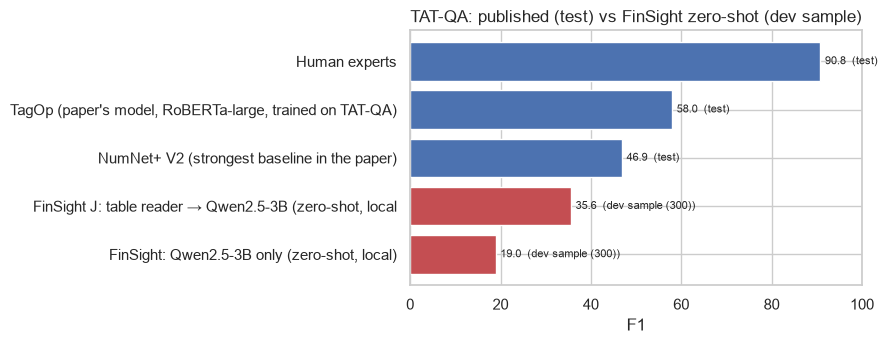

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.6))
p = published.iloc[::-1]
colors = [sns.color_palette()[3] if "FinSight" in s else sns.color_palette()[0] for s in p.system]
ax.barh(p.system.str.slice(0, 55), p.F1, color=colors)
for i, (f1, sp) in enumerate(zip(p.F1, p.split)):
    ax.text(f1 + 1, i, f"{f1:.1f}  ({sp})", va="center", fontsize=8)
ax.set_xlim(0, 100)
ax.set_xlabel("F1")
ax.set_title("TAT-QA: published (test) vs FinSight zero-shot (dev sample)")
save("tatqa")

## 5. Latency (local hardware: RTX 3050 4 GB)

In [10]:
lat = pd.concat([d1.assign(set="test v1"), d2.assign(set="test v2")])
lat = lat.groupby(["set", "config"]).latency_s.median().unstack()[list(CONFIGS)]
lat.columns = [CONFIGS[c] for c in lat.columns]
lat.round(2)

,D · hybrid + KPI table,H · statement-aware LLM,J · table reader → LLM (live)
set,,,
test v1,4.28,5.26,0.07
test v2,4.30,4.94,3.92


## 6. Publish

In [11]:
metrics_path = REPORTS_DIR / "metrics.json"
metrics = json.loads(metrics_path.read_text(encoding="utf-8"))


def records(t):
    return [{"config": i, **{k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in r.items()}}
            for i, r in t.iterrows()]


metrics["benchmarks"] = {
    "test_v1": records(t1), "test_v2": records(t2),
    "test_v2_by_kind": kinds.round(3).reset_index().to_dict("records"),
    "reader_only": {k: {kk: float(vv) for kk, vv in v.items()} for k, v in reader.items()},
    "tatqa": {"ours": tq, "published": published.to_dict("records"),
              "reader_unseen_train_sample": {"questions": 1500, "coverage": 0.198, "precision": 0.855},
              "note": "ours = 300-question stratified dev sample; published = test split; ours zero-shot"},
    "latency_median_s": lat.round(3).reset_index().to_dict("records"),
}
metrics_path.write_text(json.dumps(metrics, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print("metrics.json → benchmarks:", list(metrics["benchmarks"]))

metrics.json → benchmarks: ['test_v1', 'test_v2', 'test_v2_by_kind', 'reader_only', 'tatqa', 'latency_median_s']
